# Whole Sale Customer Record

## Part A (1)

In [8]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

WEEK_DIR = Path("")
for folder in ("data", "reports", "figures", "models"):
    (WEEK_DIR / folder).mkdir(parents=True, exist_ok=True)
data_path = WEEK_DIR / "data/wholesale_customers.csv"
if not data_path.exists():
    url = "https://archive.ics.uci.edu/static/public/292/data.csv"
    pd.read_csv(url).to_csv(data_path, index=False)
data = pd.read_csv(data_path)
print(data.head().to_string(index=False))
print("Raw shape:", data.shape)
print(data.dtypes)

 Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
       2       3  12669  9656     7561     214              2674        1338
       2       3   7057  9810     9568    1762              3293        1776
       2       3   6353  8808     7684    2405              3516        7844
       1       3  13265  1196     4221    6404               507        1788
       2       3  22615  5410     7198    3915              1777        5185
Raw shape: (440, 8)
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object


## Part A (2)

In [9]:

FEATURES = ["Fresh", "Milk", "Grocery", "Frozen",
            "Detergents_Paper", "Delicassen"]

assert data.shape == (440, 8)
assert set(data.columns) == set(FEATURES + ["Channel", "Region"])
assert data[FEATURES].apply(pd.api.types.is_numeric_dtype).all()
assert np.isfinite(data.to_numpy()).all()
assert data[FEATURES].ge(0).all().all()
assert set(data["Channel"].unique()) == {1, 2}
assert set(data["Region"].unique()) == {1, 2, 3}

print("Missing values:", int(data.isna().sum().sum()))
print("Exact duplicate rows:", int(data.duplicated().sum()))
print(data[FEATURES].describe().round(2).to_string())

customers = data.copy()
customers.insert(0, "customer_id", np.arange(1, len(customers) + 1))


Missing values: 0
Exact duplicate rows: 0
           Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
count     440.00    440.00    440.00    440.00            440.00      440.00
mean    12000.30   5796.27   7951.28   3071.93           2881.49     1524.87
std     12647.33   7380.38   9503.16   4854.67           4767.85     2820.11
min         3.00     55.00      3.00     25.00              3.00        3.00
25%      3127.75   1533.00   2153.00    742.25            256.75      408.25
50%      8504.00   3627.00   4755.50   1526.00            816.50      965.50
75%     16933.75   7190.25  10655.75   3554.25           3922.00     1820.25
max    112151.00  73498.00  92780.00  60869.00          40827.00    47943.00


# Question Answers


### A2a: Dataset Validation
The dataset has 440 customers, 6 spending features, and 2 categorical fields. Missing values and duplicates show data quality. However, passing checks does not guarantee that every record is correct.

### A2b: Spending Categories
Fresh and Grocery have the widest ranges. They can dominate Euclidean distances because larger values contribute more to the distance calculation.

### A2c: Customer ID
Customer ID should be excluded because it is only an identifier and does not represent spending behavior.

### A2d: Channel and Region
Channel and Region are categorical fields, not continuous values or correct cluster labels. They should be used only as contextual information.

### A2e: Highest Spending Customer
Highest spending does not mean highest profit. We also need product costs, profit margins, discounts, and expenses to calculate profitability.


# ---------------------------------------------------

## Part B (1)

Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicassen          11.15


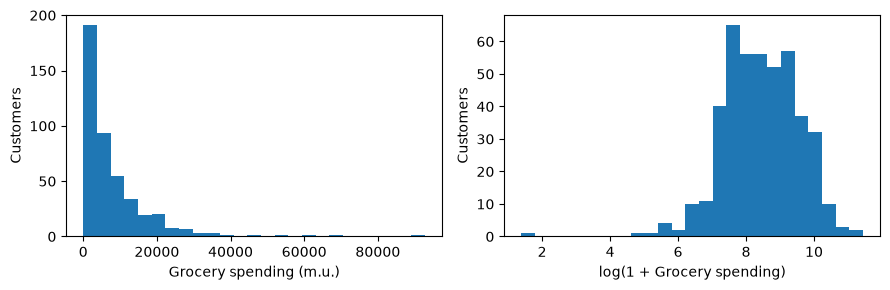

Scaled means: [ 0. -0. -0.  0. -0. -0.]
Scaled SDs: [1. 1. 1. 1. 1. 1.]


In [10]:

# Select the six spending features
X = customers[FEATURES].copy()

# Check skewness
print(X.skew().round(2).to_string())

# Compare original and log-transformed Grocery spending
fig, axes = plt.subplots(1, 2, figsize=(9, 3))

axes[0].hist(X["Grocery"], bins=25)
axes[0].set(xlabel="Grocery spending (m.u.)",
            ylabel="Customers")

axes[1].hist(np.log1p(X["Grocery"]), bins=25)
axes[1].set(xlabel="log(1 + Grocery spending)",
            ylabel="Customers")

fig.tight_layout()
fig.savefig(WEEK_DIR / "figures/spending_skew.png", dpi=200)
plt.show()

# Apply log transformation and standardisation
preprocessor = make_pipeline(
    FunctionTransformer(np.log1p, inverse_func=np.expm1,
                        validate=False),
    StandardScaler()
)

X_scaled = preprocessor.fit_transform(X)

# Check transformed data
print("Scaled means:", X_scaled.mean(axis=0).round(3))
print("Scaled SDs:", X_scaled.std(axis=0).round(3))

# Validate results
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-10)


## Part B (2)

In [11]:

representations = {
    "Raw spending": X.to_numpy(),
    "Standardised spending": StandardScaler().fit_transform(X),
    "Log plus standardisation": X_scaled,
}

reference_labels = KMeans(
    n_clusters=3, random_state=42, n_init=10
).fit_predict(X_scaled)

for name, values in representations.items():
    labels = KMeans(
        n_clusters=3, random_state=42, n_init=10
    ).fit_predict(values)

    print(
        name, "sizes:", np.bincount(labels).tolist(),
        "ARI vs log model:",
        round(adjusted_rand_score(reference_labels, labels), 3)
    )


Raw spending sizes: [330, 60, 50] ARI vs log model: 0.11
Standardised spending sizes: [45, 393, 2] ARI vs log model: 0.084
Log plus standardisation sizes: [80, 147, 213] ARI vs log model: 1.0


## Part B Question Answers


### B2a: Cluster Size and Assignments
Cluster sizes and assignments may change across representations. For example, different ARI scores show that preprocessing affects customer grouping.

### B2b: High-Spending Account
A valid high-spending account should remain in the analysis. Before excluding an unusual record, we should check for data entry errors and confirm whether the spending is genuine.

### B2c: Effect of Transformation and Scaling
Log transformation and scaling change feature values and distances, resulting in different clusters. Inertia values are not directly comparable because each representation uses a different numerical scale.


# ---------------------------------------------------

## Part C (1)

 k  inertia  silhouette  smallest  largest
 1 2640.000         NaN       440      440
 2 1844.064       0.290       188      252
 3 1553.421       0.259        80      213
 4 1386.863       0.188        61      132
 5 1266.149       0.192        54      100
 6 1174.759       0.201        20      114
 7 1086.359       0.196        20      118
 8 1028.486       0.185        13      103


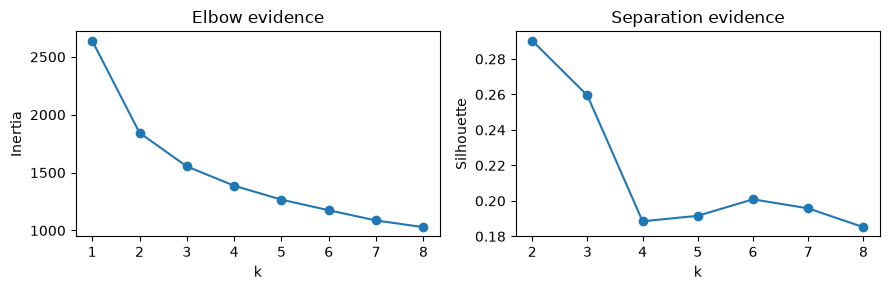

In [12]:

candidate_rows = []
candidates = {}

for k in range(1, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    candidates[k] = (model, labels)

    counts = pd.Series(labels).value_counts()
    n_labels = len(counts)

    score = (silhouette_score(X_scaled, labels)
             if 2 <= n_labels < len(X_scaled) else np.nan)

    candidate_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": score,
        "smallest": counts.min(),
        "largest": counts.max()
    })

comparison = pd.DataFrame(candidate_rows)
comparison.to_csv(WEEK_DIR / "reports/k_evaluation.csv", index=False)

print(comparison.round(3).to_string(index=False))

# Plot elbow and silhouette graphs
fig, axes = plt.subplots(1, 2, figsize=(9, 3))

axes[0].plot(comparison["k"], comparison["inertia"], marker="o")
axes[0].set(xlabel="k", ylabel="Inertia", title="Elbow evidence")

axes[1].plot(comparison["k"], comparison["silhouette"], marker="o")
axes[1].set(xlabel="k", ylabel="Silhouette", title="Separation evidence")

fig.tight_layout()
fig.savefig(WEEK_DIR / "figures/k_evaluation.png", dpi=200)
plt.show()


## Part C (2)

In [13]:

shortlist = [2, 3, 4]

for k in shortlist:
    labels = candidates[k][1]
    trial = customers.assign(cluster=labels)

    counts = trial.groupby("cluster").size()

    print("\nk =", k, "sizes:", counts.to_dict())
    print("Median category spending (m.u.):")

    print(
        trial.groupby("cluster")[FEATURES]
        .median()
        .round(1)
        .to_string()
    )



k = 2 sizes: {0: 252, 1: 188}
Median category spending (m.u.):
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0        10347.5  1871.0   2406.0  2225.0             327.5       749.5
1         5406.5  7690.5  11527.0  1061.5            4495.0      1388.5

k = 3 sizes: {0: 80, 1: 147, 2: 213}
Median category spending (m.u.):
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0         1492.5  6300.5  10502.5   376.0            4217.5       434.5
1        12126.0  7184.0   9965.0  2005.0            3378.0      2005.0
2         9612.0  1601.0   2155.0  2121.0             274.0       686.0

k = 4 sizes: {0: 61, 1: 129, 2: 132, 3: 118}
Median category spending (m.u.):
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                           

## Part C Question Answers


### C2a: Selecting K Values

I would shortlist k = 2, 3, and 4 for further inspection. These values provide a reasonable balance between cluster separation, inertia reduction, and cluster sizes.

### C2b: Pilot Cluster Selection

I would choose k = 3 for the pilot because it provides a balance between readable customer segments and operational simplicity. However, the silhouette score, cluster sizes, and spending patterns must also be considered. If one cluster is too small or the groups are not clearly separated, another value of k may be more suitable. Business usefulness is more important than selecting the highest silhouette score alone.

### C2c: Small and Dominant Clusters

No, I would not automatically select it. I would inspect cluster sizes, spending patterns, and customer characteristics to ensure the groups are useful and meaningful for the business team.


# ---------------------------------------------------

## Part D (1)